## **NLP Sentiment Classification on Customer Reviews (TF-IDF)**

In [15]:
# Importing libraries
import re
import pandas as pd
import matplotlib.pyplot as plt

# NLTK gives us the stopword list and the lemmatizer
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# scikit-learn gives us TF-IDF, the two models, and the evaluation tools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# download the NLTK word lists (only downloads the first time)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

True

In [16]:
# Load the data
# read the CSV file into a table (DataFrame)
df = pd.read_csv("sentiment_reviews.csv")

# keep only positive and negative reviews (2-class task, so "neutral" is dropped)
df = df[df["sentiment"].isin(["positive", "negative"])].reset_index(drop=True)

print(len(df), "reviews kept")
print(df["sentiment"].value_counts())

9 reviews kept
sentiment
positive    5
negative    4
Name: count, dtype: int64


In [17]:
# 2. Clean text: lowercase, letters only, remove stopwords, lemmatize
# (keep "not", "no" etc. because they flip the meaning of a sentence)
stop_words = set(stopwords.words("english")) - {"no", "nor", "not", "never", "nothing", "none", "neither", "cannot"}
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r"[^a-z\s]", " ", re.sub(r"<[^>]+>", " ", text.lower()))
    words = [w for w in text.split() if w not in stop_words]
    return " ".join(lemmatizer.lemmatize(lemmatizer.lemmatize(w, "v"), "n") for w in words)

X = df["review_text"].apply(clean_text)
y = df["sentiment"]


In [18]:
# 3. Two models: TF-IDF (text -> numbers) followed by a classifier
models = {
    "MultinomialNB": make_pipeline(TfidfVectorizer(max_features=5000, ngram_range=(1, 2)), MultinomialNB()),
    "LogisticRegression": make_pipeline(TfidfVectorizer(max_features=5000, ngram_range=(1, 2)), LogisticRegression(max_iter=1000, C=10)),
}

=== MultinomialNB accuracy: 0.111
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         4
    positive       0.20      0.20      0.20         5

    accuracy                           0.11         9
   macro avg       0.10      0.10      0.10         9
weighted avg       0.11      0.11      0.11         9

=== LogisticRegression accuracy: 0.111
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         4
    positive       0.20      0.20      0.20         5

    accuracy                           0.11         9
   macro avg       0.10      0.10      0.10         9
weighted avg       0.11      0.11      0.11         9



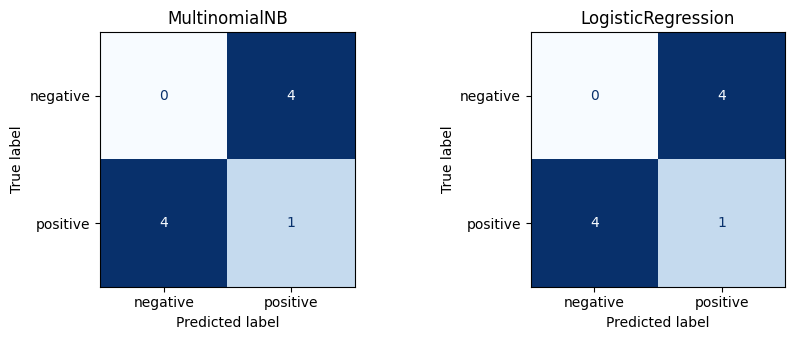

In [19]:
# 4. Test each model with Leave-One-Out (train on 8 reviews, test on the 1 left out)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, model) in zip(axes, models.items()):
    preds = cross_val_predict(model, X, y, cv=LeaveOneOut())
    print("===", name, "accuracy:", round(accuracy_score(y, preds), 3))
    print(classification_report(y, preds, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y, preds, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()


In [20]:
# 5. Train on all data, show the most important words
for model in models.values():
    model.fit(X, y)
lr = models["LogisticRegression"]
ranked = sorted(zip(lr[-1].coef_[0], lr[0].get_feature_names_out()))
print("Most negative:", ", ".join(w for _, w in ranked[:10]))
print("Most positive:", ", ".join(w for _, w in ranked[::-1][:10]))


Most negative: day, day extremely, disappoint, disappoint purchase, extremely, extremely disappoint, stop, stop work, two, two day
Most positive: setup, quality exceptional, quality, product quality, product, expectation, exceptional exceed, exceptional, exceed expectation, exceed


In [21]:
# 6. Predict your own sentences
def predict_sentiment(text, model_name="LogisticRegression"):
    model = models[model_name]
    probs = model.predict_proba([clean_text(text)])[0]
    return model.classes_[probs.argmax()], probs.max()

tests = [
    "Absolutely love it, works great and arrived quickly!",
    "Broke after one day, total waste of money.",
    "Not worth the price, very disappointed.",
    "Support was helpful and the setup was easy.",
]
for t in tests:
    for name in models:
        label, conf = predict_sentiment(t, name)
        print(f"[{name:<18}] {label:<9} ({conf:.2f})  <- {t}")

[MultinomialNB     ] positive  (0.62)  <- Absolutely love it, works great and arrived quickly!
[LogisticRegression] positive  (0.68)  <- Absolutely love it, works great and arrived quickly!
[MultinomialNB     ] negative  (0.56)  <- Broke after one day, total waste of money.
[LogisticRegression] negative  (0.64)  <- Broke after one day, total waste of money.
[MultinomialNB     ] negative  (0.58)  <- Not worth the price, very disappointed.
[LogisticRegression] negative  (0.67)  <- Not worth the price, very disappointed.
[MultinomialNB     ] positive  (0.66)  <- Support was helpful and the setup was easy.
[LogisticRegression] positive  (0.75)  <- Support was helpful and the setup was easy.


In [ ]:
# 7. Type your own reviews (press Enter or q to stop)
while True:
    text = input("review> ").strip()
    if text.lower() in ("q", ""):
        break
    for name in models:
        label, conf = predict_sentiment(text, name)
        print(f"  {name:<18} -> {label} ({conf:.3f})")